# Chaotic stirring 2: a tidal current over residual eddies

**37EFM Environmental Fluid Mechanics, TU/e**

In a shallow tidal basin, the tide carries the water back and forth over residual eddies, the slow circulations that form behind headlands and around islands. Ridderinkhof and Zimmerman (1992) traced the dispersion of tracers in the western Dutch Wadden Sea to chaotic stirring of this kind, and Beerens et al. (1994) analysed it in a kinematic model: a uniform tidal current over a steady, periodic array of eddies (Chapter 7 of the lecture notes, section *Chaotic advection in the environment*). In dimensionless form, with time in units of $1/\omega$ (one tide lasts $2\pi$) and lengths such that one eddy is a square of side $\pi$,

$$u = A\cos t + \nu \sin x \cos y, \qquad v = -\nu \cos x \sin y .$$

The residual stream function is $\nu \sin x \sin y$, so neighbouring eddies turn in opposite directions, and no water crosses $y = 0$ or $y = \pi$. The tidal displacement is $A \sin t$, so the tidal excursion, from one slack water to the next, is $2A$, and the two parameters are

$$\frac{\text{tidal excursion}}{\text{eddy size}} = \frac{2A}{\pi}, \qquad \frac{\text{residual speed}}{\text{tidal speed}} = \frac{\nu}{A}.$$

The defaults are those of the figure in the notes: an excursion of 0.8 eddy sizes, and a residual current half the tidal one ($A = 1.25$, $\nu = 0.625$). Unlike the blinking vortex, this flow is integrated numerically, with a fourth-order Runge-Kutta scheme.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import efmstir
from efmstir import lyapunov as L
plt.rcParams['figure.dpi'] = 80

flow = efmstir.TidalEddies()          # A = 1.25, nu = 0.625
TIDE = flow.period                    # 2 pi
print(flow)

def eddy_lines(ax, xmin=-3 * np.pi, xmax=3 * np.pi):
    for k in range(int(np.floor(xmin / np.pi)), int(np.ceil(xmax / np.pi)) + 1):
        ax.axvline(k * np.pi, color='0.6', lw=0.6)
    ax.set_ylim(0, np.pi)

TidalEddies(A=1.25, nu=0.625: excursion 0.796 eddy sizes, residual/tidal 0.5)


## The flow

Streamlines at four phases of the tide. At $t = 0$ the tidal current is at its strongest, flowing in the $+x$ direction, and the tidal displacement is zero; at $t = \pi/2$ the current is slack, at $t = \pi$ it is strongest in the $-x$ direction. The grey lines are the boundaries of the eddies.

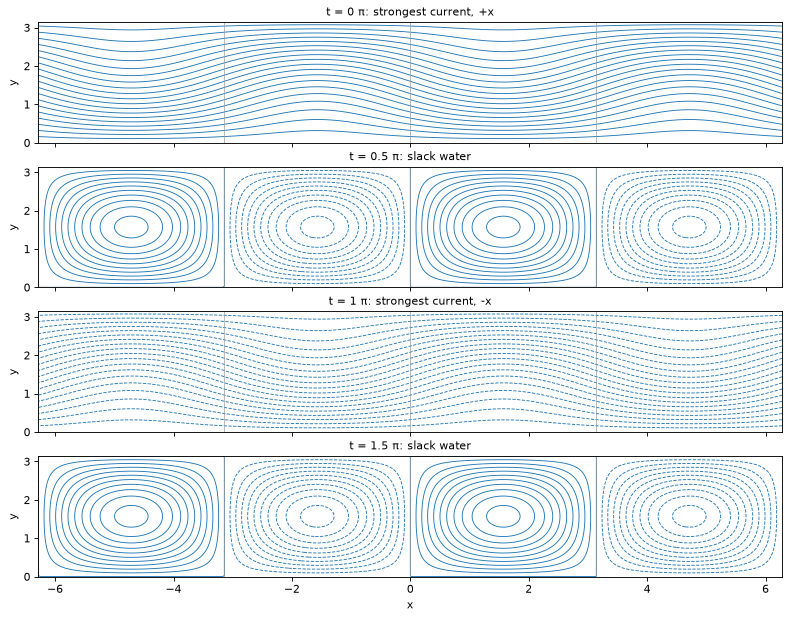

In [2]:
xg, yg = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 400), np.linspace(0, np.pi, 100))
fig, axs = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, (t, name) in zip(axs, [(0, 'strongest current, +x'), (np.pi / 2, 'slack water'),
                               (np.pi, 'strongest current, -x'), (3 * np.pi / 2, 'slack water')]):
    ax.contour(xg, yg, flow.streamfunction(xg, yg, t), levels=21, colors='C0', linewidths=0.8)
    eddy_lines(ax, -2 * np.pi, 2 * np.pi)
    ax.set_xlim(-2 * np.pi, 2 * np.pi); ax.set_ylabel('y')
    ax.set_title(f't = {t / np.pi:g} π: {name}', fontsize=10)
axs[-1].set_xlabel('x');

## Poincaré section

Parcels are recorded once per tide, at $t = 0, 2\pi, 4\pi, \dots$ Because the flow repeats every $2\pi$ in $x$, positions are folded back into one pair of eddies, $-\pi \le x < \pi$. The parcels start on the line $y = \pi/2$, across both eddies, and are followed for 500 tides.

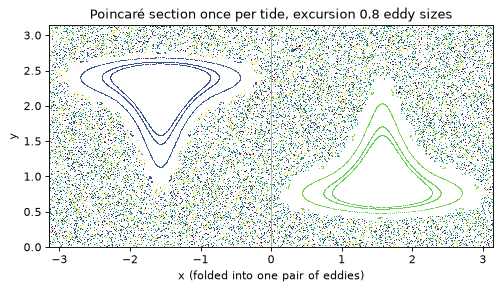

In [3]:
fast = efmstir.TidalEddies(steps=32)          # coarser time step: enough for a Poincare section
seeds_x = np.linspace(-np.pi, np.pi, 49)[:-1]
x, y = seeds_x.copy(), np.full_like(seeds_x, np.pi / 2)
pts = []
for k in range(500):
    x, y = fast.period_map(x, y)
    pts.append((np.mod(x + np.pi, 2 * np.pi) - np.pi, y.copy()))
pts = np.array(pts)

colours = plt.cm.viridis(np.linspace(0, 1, seeds_x.size))
fig, ax = plt.subplots(figsize=(12, 3.6))
for i in range(seeds_x.size):
    ax.plot(pts[:, 0, i], pts[:, 1, i], ',', color=colours[i])
eddy_lines(ax, -np.pi, np.pi)
ax.set_xlim(-np.pi, np.pi); ax.set_aspect('equal'); ax.set_xlabel('x (folded into one pair of eddies)'); ax.set_ylabel('y')
ax.set_title('Poincaré section once per tide, excursion 0.8 eddy sizes');

## Two blobs of dye

As in the figure of Chapter 7: a blob released between two eddies, at $(0, \pi/2)$, and one released at $(\pi/2, \pi/3)$, inside an eddy, both at $t = 0$, followed for six tides.

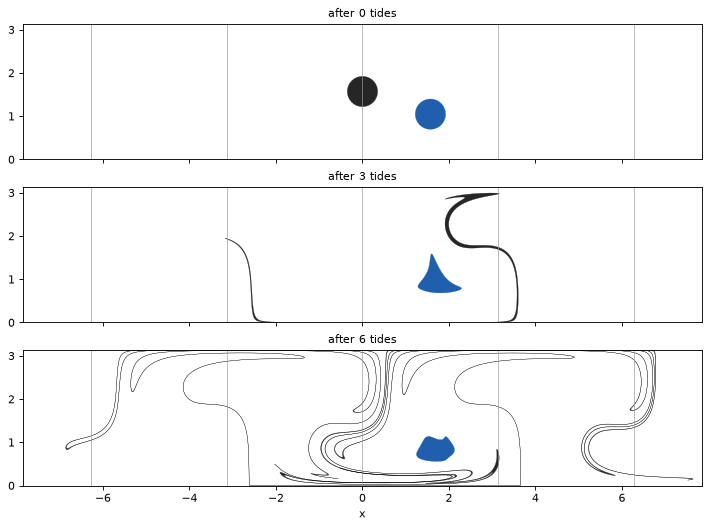

In [4]:
releases = {'between two eddies': ((0.0, np.pi / 2), '#262626'),
            'inside an eddy': ((np.pi / 2, np.pi / 3), '#1F5FAD')}
blob = {name: L.follow_outline(flow, *L.outline(*xy, 0.35), 0.0, 6, h=0.01)
        for name, (xy, _) in releases.items()}

fig, axs = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, n in zip(axs, (0, 3, 6)):
    for name, (_, colour) in releases.items():
        xo, yo = blob[name][n]
        ax.fill(xo, yo, color=colour, lw=0)
        ax.plot(np.r_[xo, xo[0]], np.r_[yo, yo[0]], color=colour, lw=0.25)
    eddy_lines(ax, -2.5 * np.pi, 2.5 * np.pi)
    ax.set_xlim(-2.5 * np.pi, 2.5 * np.pi); ax.set_aspect('equal')
    ax.set_title(f'after {n} tides', fontsize=10)
axs[-1].set_xlabel('x');

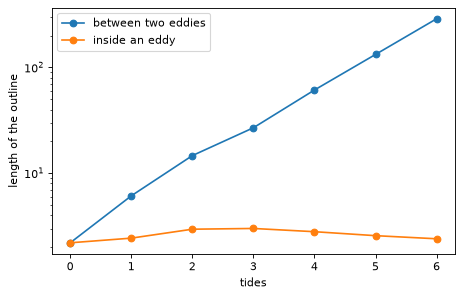

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, run in blob.items():
    ax.semilogy(range(len(run)), [L.length(*o) for o in run], 'o-', label=name)
ax.set_xlabel('tides'); ax.set_ylabel('length of the outline'); ax.legend();

## The Lyapunov exponent, and where stirring is strongest

The Lyapunov exponent of parcels started at random over a pair of eddies, after 150 tides, per tide. Those with $\lambda > 0.1$ per tide are counted as chaotic.

73% of the parcels are chaotic; their Lyapunov exponent is 0.53 per tide


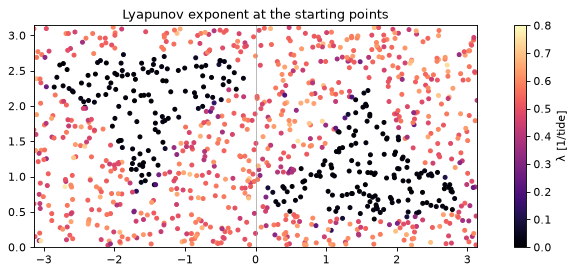

In [6]:
rng = np.random.default_rng(0)
xs, ys = rng.uniform(-np.pi, np.pi, 1000), rng.uniform(0.02, np.pi - 0.02, 1000)
lam = L.lyapunov(fast, xs, ys, 150)[-1] * TIDE              # per tide
chaotic = lam > 0.1
lam_sea = np.median(lam[chaotic])
print(f'{chaotic.mean():.0%} of the parcels are chaotic; their Lyapunov exponent is {lam_sea:.2f} per tide')

fig, ax = plt.subplots(figsize=(12, 3.6))
sc = ax.scatter(xs, ys, c=lam, s=12, cmap='magma', vmin=0, vmax=0.8)
eddy_lines(ax, -np.pi, np.pi); ax.set_xlim(-np.pi, np.pi); ax.set_aspect('equal')
fig.colorbar(sc, ax=ax, label='λ [1/tide]'); ax.set_title('Lyapunov exponent at the starting points');

In a real basin the eddies are fixed by the topography, and it is the tide that varies, from neap to spring and from one basin to the next. Keep the eddies as they are ($\nu = 0.625$) and vary the tidal amplitude $A$, and with it the excursion:

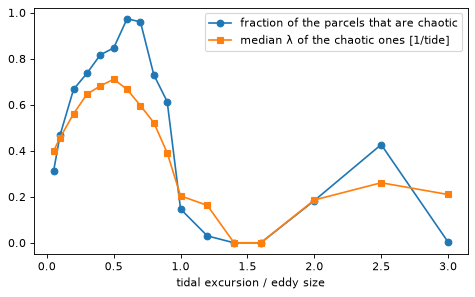

In [7]:
excursions = np.array([0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.4, 1.6, 2.0, 2.5, 3.0])
xs2, ys2 = xs[:300], ys[:300]
frac, lam_med = [], []
for e in excursions:
    f = efmstir.TidalEddies(A=e * np.pi / 2, nu=0.625, steps=32)
    l = L.lyapunov(f, xs2, ys2, 150)[-1] * TIDE
    frac.append(np.mean(l > 0.1))
    lam_med.append(np.median(l[l > 0.1]) if np.any(l > 0.1) else 0.0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(excursions, frac, 'o-', label='fraction of the parcels that are chaotic')
ax.plot(excursions, lam_med, 's-', label='median λ of the chaotic ones [1/tide]')
ax.set_xlabel('tidal excursion / eddy size'); ax.legend();

Stirring is strongest when the tide carries the water over half to three quarters of an eddy, and nearly vanishes once the excursion exceeds an eddy size, apart from partial revivals at some larger excursions. With 300 parcels per point the curve is somewhat noisy; more parcels, or longer runs, sharpen it.

## Finite-time Lyapunov exponents

The FTLE over 1, 3 and 6 tides, forward from $t = 0$ (see the blinking-vortex notebook for the definition).

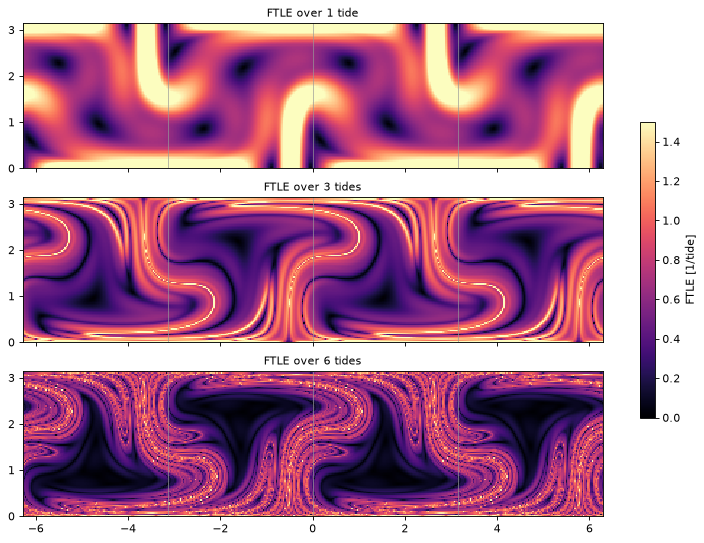

In [8]:
X, Y = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 401), np.linspace(0.005, np.pi - 0.005, 101))
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, n in zip(axs, (1, 3, 6)):
    f = L.ftle(flow, X, Y, 0.0, n * TIDE) * TIDE
    im = ax.pcolormesh(X, Y, f, vmin=0, vmax=1.5, cmap='magma', shading='auto')
    eddy_lines(ax, -2 * np.pi, 2 * np.pi)
    ax.set_xlim(-2 * np.pi, 2 * np.pi); ax.set_aspect('equal')
    ax.set_title(f'FTLE over {n} tide{"s" if n > 1 else ""}', fontsize=10)
fig.colorbar(im, ax=axs, shrink=0.6, label='FTLE [1/tide]');

The dye released between the eddies, after six tides, on top of the backward FTLE at that moment, computed over the same six tides. The filaments lie along its ridges, the lines that have attracted the fluid over the last six tides.

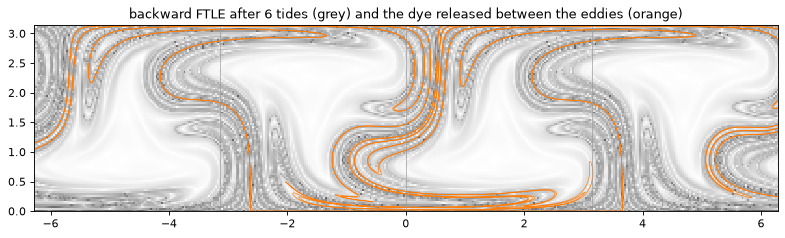

In [9]:
f_back = L.ftle(flow, X, Y, 6 * TIDE, -6 * TIDE) * TIDE
xo, yo = blob['between two eddies'][6]
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.pcolormesh(X, Y, f_back, vmin=0, vmax=1.5, cmap='Greys', shading='auto', alpha=0.6)
ax.plot(np.r_[xo, xo[0]], np.r_[yo, yo[0]], color='C1', lw=0.6)
eddy_lines(ax, -2 * np.pi, 2 * np.pi)
ax.set_xlim(-2 * np.pi, 2 * np.pi); ax.set_aspect('equal')
ax.set_title('backward FTLE after 6 tides (grey) and the dye released between the eddies (orange)');

## Finite-size Lyapunov exponents

The FSLE $\lambda(\delta)$ for pairs started in the chaotic sea, from $\delta = 10^{-8}$ to many eddy sizes. At small separations it is the Lyapunov exponent. Once two parcels are an eddy apart, they are no longer separated by a velocity gradient but carried by different eddies, and each one's journey from eddy to eddy is a random walk. A random walk spreads as $\delta^2 \sim D_{\text{eff}}\, t$, so the time to double a separation grows as $\delta^2$, and

$$\lambda(\delta) \propto \frac{D_{\text{eff}}}{\delta^2}$$

at scales larger than the eddies: chaotic stirring at the eddy scale acts as a diffusion at larger scales. Only the separations that at least 90 % of the pairs reached within the run are shown; at larger ones, the pairs still missing would be the slow ones, and leaving them out would bias the FSLE upward. Within 800 tides, the pairs get to about five eddy sizes, and over that last decade the FSLE falls close to $\delta^{-2}$.

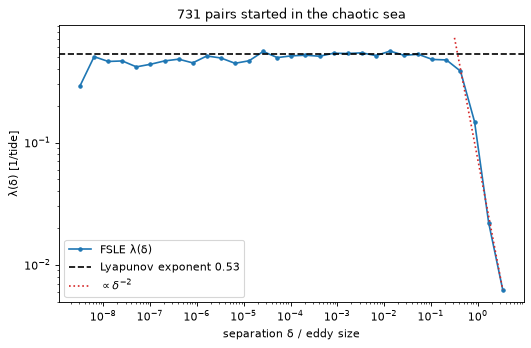

In [10]:
sea_x, sea_y = xs[chaotic][:800], ys[chaotic][:800]
delta, fsle, npairs = L.fsle_curve(fast, sea_x, sea_y, delta0=1e-8, ratio=2.0, n_scales=33, t_max=800 * TIDE)
fsle = fsle * TIDE
reached = npairs >= 0.9 * sea_x.size        # scales that nearly all pairs reached within the run
delta, fsle = delta[reached], fsle[reached]
large = delta > 2 * np.pi
c = np.median(fsle[large] * delta[large] ** 2)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(delta / np.pi, fsle, 'o-', ms=3, label='FSLE λ(δ)')
ax.axhline(lam_sea, color='k', ls='--', label=f'Lyapunov exponent {lam_sea:.2f}')
dd = np.logspace(0, np.log10(delta.max()), 20)
ax.loglog(dd / np.pi, c / dd ** 2, ':', color='C3', label=r'$\propto \delta^{-2}$')
ax.set_xlabel('separation δ / eddy size'); ax.set_ylabel('λ(δ) [1/tide]'); ax.legend(loc='lower left')
ax.set_title(f'{sea_x.size} pairs started in the chaotic sea');

Like the FTLE, the FSLE can be mapped over the starting points (d'Ovidio et al. 2004 did this for the Mediterranean Sea, from satellite currents). Each point gets four neighbours at $\delta_0 = 0.02$, and $\lambda = \ln(\delta_f/\delta_0)/\tau$, with $\tau$ the time until one of them is $\delta_f = 1$ away, about a third of an eddy.

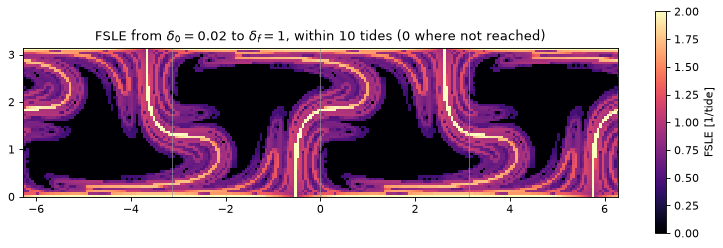

In [11]:
Xf, Yf = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 241), np.linspace(0.01, np.pi - 0.01, 61))
f = L.fsle_field(flow, Xf, Yf, delta0=0.02, delta_f=1.0, t_max=10 * TIDE, dt=TIDE / 16) * TIDE
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.pcolormesh(Xf, Yf, f, vmin=0, vmax=2.0, cmap='magma', shading='auto')
eddy_lines(ax, -2 * np.pi, 2 * np.pi); ax.set_xlim(-2 * np.pi, 2 * np.pi); ax.set_aspect('equal')
fig.colorbar(im, ax=ax, label='FSLE [1/tide]')
ax.set_title(r'FSLE from $\delta_0 = 0.02$ to $\delta_f = 1$, within 10 tides (0 where not reached)');

## In physical units

A tide lasts $T = 12.42$ h. If an eddy is, say, 5 km across, one unit of length is $5/\pi$ km and one unit of speed is $(5/\pi\ \text{km})\,\omega$. For a random walk along the channel with diffusivity $D$, the separation of two parcels diffuses with $2D$, and the mean time for it to grow from $\delta$ to $2\delta$ is $3\delta^2/(4D)$. With $\lambda(\delta) = \ln 2/\tau$, the $\delta^{-2}$ range of the FSLE gives the effective diffusivity, $D_{\text{eff}} = \tfrac{3}{4\ln 2}\,\lambda\delta^2$.

In [12]:
T_hours = 12.42
eddy_km = 5.0
unit_km = eddy_km / np.pi
omega = 2 * np.pi / (T_hours * 3600)
print(f'tidal current amplitude      {flow.A * unit_km * 1e3 * omega:.2f} m/s')
print(f'residual current             {flow.nu * unit_km * 1e3 * omega:.2f} m/s')
print(f'Lyapunov exponent            {lam_sea:.2f} per tide = {lam_sea / T_hours:.3f} per hour')
print(f'e-folding time of stretching {T_hours / lam_sea:.0f} h')
D_eff = 3 / (4 * np.log(2)) * (c / TIDE) * (unit_km * 1e3) ** 2 * omega   # c / TIDE: lambda * delta^2 per unit time
print(f'effective along-channel diffusivity {D_eff:.0f} m^2/s')

tidal current amplitude      0.28 m/s
residual current             0.14 m/s
Lyapunov exponent            0.53 per tide = 0.043 per hour
e-folding time of stretching 23 h
effective along-channel diffusivity 44 m^2/s


## Questions

1. Release the two blobs at slack water, $t_0 = \pi/2$, instead of at $t = 0$ (`L.follow_outline(flow, x, y, np.pi / 2, 6)`). Does the blob inside the eddy still stay on a regular island? Compute a Poincaré section at that phase (`fast.period_map(x, y, t0=np.pi / 2)`) and compare it with the one at $t = 0$.
2. Why does the chaos fade when the tidal excursion is much larger than an eddy? What does a parcel feel of the eddies when the tide carries it across many of them in one tide? And why does it fade when the excursion is very small?
3. Where do the ridges of the forward FTLE lie relative to the boundaries of the eddies? Why there?
4. Show that for two parcels each doing a random walk with diffusivity $D$ along a line, the mean time for their separation to grow from $\delta$ to $2\delta$ is $3\delta^2/(4D)$. (The separation diffuses with $2D$; solve $2D\,T'' = -1$ with $T'(0) = 0$ and $T(2\delta) = 0$.) How does the effective diffusivity computed above compare with the turbulent diffusivities of Chapter 6? How does it change with the size of the eddies, at the same tidal period?
5. A patch of polluted water 1 km across is released between two eddies. Use the FSLE curve to estimate how long it takes to be spread over one eddy, and over ten.

### References

- Artale, V., Boffetta, G., Celani, A., Cencini, M. and Vulpiani, A. (1997). Dispersion of passive tracers in closed basins: beyond the diffusion coefficient. *Physics of Fluids* 9, 3162–3171.
- Aurell, E., Boffetta, G., Crisanti, A., Paladin, G. and Vulpiani, A. (1997). Predictability in the large: an extension of the concept of Lyapunov exponent. *Journal of Physics A* 30, 1–26.
- Beerens, S. P., Ridderinkhof, H. and Zimmerman, J. T. F. (1994). An analytical study of chaotic stirring in tidal areas. *Chaos, Solitons & Fractals* 4, 1011–1029.
- d'Ovidio, F., Fernández, V., Hernández-García, E. and López, C. (2004). Mixing structures in the Mediterranean Sea from finite-size Lyapunov exponents. *Geophysical Research Letters* 31, L17203.
- Ridderinkhof, H. and Zimmerman, J. T. F. (1992). Chaotic stirring in a tidal system. *Science* 258, 1107–1111.